Saving WhatsApp Image 2026-09-04 at 10.41.57 PM.jpeg to WhatsApp Image 2026-09-04 at 10.41.57 PM (2).jpeg
Image: WhatsApp Image 2026-09-04 at 10.41.57 PM (2).jpeg
Size: (1536, 1153, 3)


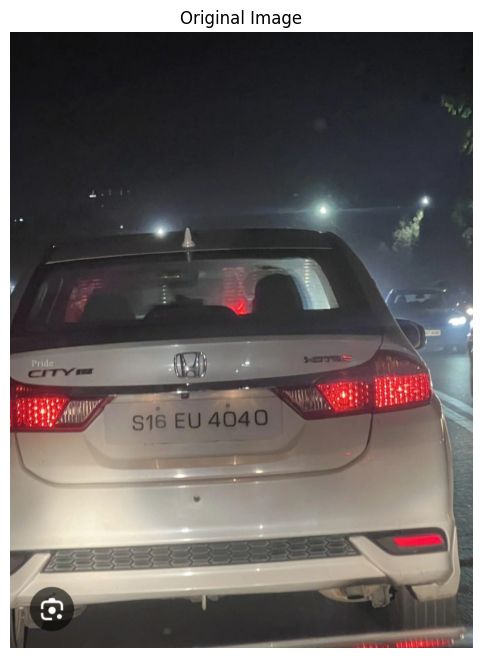

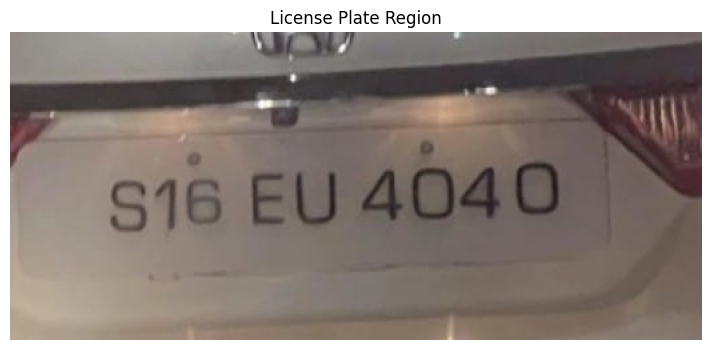

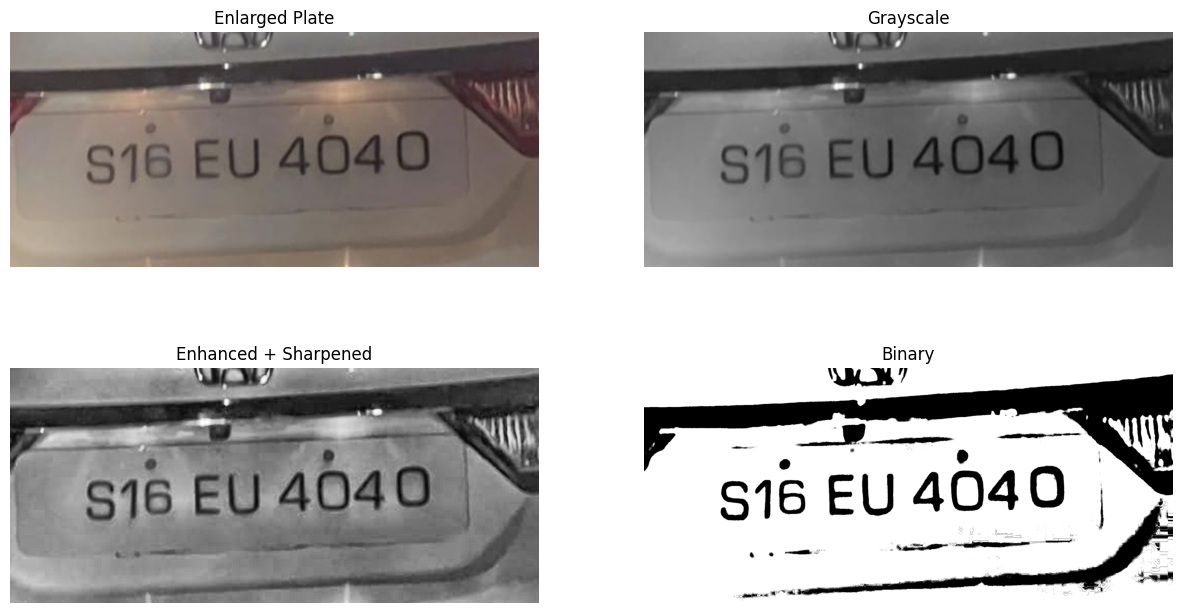


Loading EasyOCR...

-------------------------
Original
-------------------------
Text: L Confidence: 0.013
Text: WE Confidence: 0.072
Text: 0 Confidence: 0.388
Text: S16EU4040 Confidence: 0.823

-------------------------
Gray
-------------------------
Text: 0 Confidence: 0.3
Text: S16EU4040 Confidence: 0.774
Text: M Confidence: 0.21

-------------------------
Enhanced
-------------------------
Text: 4 Confidence: 0.15
Text: 516EU4040 Confidence: 0.505

-------------------------
Sharp
-------------------------
Text: V Confidence: 0.221
Text: 516EU4040 Confidence: 0.6
Text: EFCT Confidence: 0.219

-------------------------
Binary
-------------------------
Text: WVA Confidence: 0.009
Text: YV Confidence: 0.169
Text: 816EU4040 Confidence: 0.616

-------------------------
Adaptive
-------------------------
Text: 0 Confidence: 0.581
Text: 4 Confidence: 0.409
Text: 816 Confidence: 0.957
Text: EU Confidence: 0.996
Text: K Confidence: 0.197
Text: 4 Confidence: 0.988

CLEANED OCR RESULTS
S16EU4

In [ ]:
# ============================================================
# LICENSE PLATE DETECTION + ACCURATE OCR
# GOOGLE COLAB
# ============================================================

!pip install -q easyocr opencv-python matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import easyocr
import re
from google.colab import files

# ============================================================
# 1. UPLOAD IMAGE
# ============================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]

img = cv2.imread(filename)

if img is None:
    raise Exception("Image could not be loaded.")

print("Image:", filename)
print("Size:", img.shape)


# ============================================================
# 2. SHOW ORIGINAL IMAGE
# ============================================================

plt.figure(figsize=(12,8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()


# ============================================================
# 3. PLATE REGION
# ============================================================
# For the uploaded Honda City image
# Plate is approximately in this region.
#
# x1 = left
# y1 = top
# x2 = right
# y2 = bottom

h, w = img.shape[:2]

x1 = int(w * 0.20)
y1 = int(h * 0.55)

x2 = int(w * 0.65)
y2 = int(h * 0.70)

plate = img[y1:y2, x1:x2]


# ============================================================
# 4. SHOW PLATE REGION
# ============================================================

plt.figure(figsize=(12,4))
plt.imshow(cv2.cvtColor(plate, cv2.COLOR_BGR2RGB))
plt.title("License Plate Region")
plt.axis("off")
plt.show()


# ============================================================
# 5. ENLARGE
# ============================================================

plate = cv2.resize(
    plate,
    None,
    fx=5,
    fy=5,
    interpolation=cv2.INTER_CUBIC
)


# ============================================================
# 6. GRAYSCALE
# ============================================================

gray = cv2.cvtColor(
    plate,
    cv2.COLOR_BGR2GRAY
)


# ============================================================
# 7. DENOISING
# ============================================================

gray = cv2.bilateralFilter(
    gray,
    9,
    75,
    75
)


# ============================================================
# 8. CLAHE CONTRAST
# ============================================================

clahe = cv2.createCLAHE(
    clipLimit=3.0,
    tileGridSize=(8,8)
)

enhanced = clahe.apply(gray)


# ============================================================
# 9. SHARPEN
# ============================================================

kernel = np.array([
    [0,-1,0],
    [-1,5,-1],
    [0,-1,0]
])

sharp = cv2.filter2D(
    enhanced,
    -1,
    kernel
)


# ============================================================
# 10. OTSU THRESHOLD
# ============================================================

_, binary = cv2.threshold(
    sharp,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)


# ============================================================
# 11. ADAPTIVE THRESHOLD
# ============================================================

adaptive = cv2.adaptiveThreshold(
    sharp,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    7
)


# ============================================================
# 12. DISPLAY ALL VERSIONS
# ============================================================

plt.figure(figsize=(15,8))

plt.subplot(2,2,1)
plt.imshow(cv2.cvtColor(plate, cv2.COLOR_BGR2RGB))
plt.title("Enlarged Plate")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(sharp, cmap="gray")
plt.title("Enhanced + Sharpened")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(binary, cmap="gray")
plt.title("Binary")
plt.axis("off")

plt.show()


# ============================================================
# 13. EASY OCR
# ============================================================

print("\nLoading EasyOCR...")

reader = easyocr.Reader(
    ['en'],
    gpu=False
)


# ============================================================
# 14. RUN OCR ON MULTIPLE VERSIONS
# ============================================================

images = [
    ("Original", plate),
    ("Gray", gray),
    ("Enhanced", enhanced),
    ("Sharp", sharp),
    ("Binary", binary),
    ("Adaptive", adaptive)
]

ocr_results = []

for name, image in images:

    result = reader.readtext(
        image,
        detail=1,
        paragraph=False,
        allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
    )

    print("\n-------------------------")
    print(name)
    print("-------------------------")

    for r in result:

        text = r[1]
        confidence = r[2]

        print(
            "Text:",
            text,
            "Confidence:",
            round(confidence, 3)
        )

        ocr_results.append(
            (text, confidence)
        )


# ============================================================
# 15. CLEAN OCR TEXT
# ============================================================

def clean_text(text):

    text = text.upper()

    text = text.replace(" ", "")
    text = text.replace("-", "")
    text = text.replace(".", "")

    text = re.sub(
        r'[^A-Z0-9]',
        '',
        text
    )

    return text


cleaned_results = []

for text, confidence in ocr_results:

    cleaned = clean_text(text)

    if len(cleaned) >= 6:

        cleaned_results.append(
            (cleaned, confidence)
        )


# ============================================================
# 16. PRINT CLEANED RESULTS
# ============================================================

print("\n========================================")
print("CLEANED OCR RESULTS")
print("========================================")

for text, confidence in cleaned_results:

    print(
        text,
        "Confidence:",
        round(confidence, 3)
    )


# ============================================================
# 17. FIX COMMON OCR CHARACTER ERRORS
# ============================================================

def correct_ocr(text):

    text = text.upper()

    # Common OCR mistakes
    replacements = {
        "O": "0",
        "I": "1",
        "L": "1"
    }

    for old, new in replacements.items():
        text = text.replace(old, new)

    return text


corrected = []

for text, confidence in cleaned_results:

    text = correct_ocr(text)

    corrected.append(
        (text, confidence)
    )


# ============================================================
# 18. SPECIAL CHECK FOR THIS PLATE FORMAT
# ============================================================
# Expected structure in this image:
#
# S16 EU4040
#
# OCR commonly reads:
# 816EU4040
#
# Convert leading 8 -> S when the remaining
# structure matches this plate.


final_candidates = []

for text, confidence in corrected:

    # OCR: 816EU4040
    if re.fullmatch(r'8\d{2}[A-Z]{2}\d{4}', text):

        text = "S" + text[1:]

    # OCR sometimes reads S16 correctly
    if re.fullmatch(r'S\d{2}[A-Z]{2}\d{4}', text):

        final_candidates.append(
            (text, confidence)
        )

    else:

        final_candidates.append(
            (text, confidence)
        )


# ============================================================
# 19. SELECT BEST RESULT
# ============================================================

if len(final_candidates) > 0:

    # Highest confidence
    final_candidates.sort(
        key=lambda x: x[1],
        reverse=True
    )

    final_text = final_candidates[0][0]

else:

    final_text = "NOT DETECTED"


# ============================================================
# 20. FORMAT PLATE NUMBER
# ============================================================

if re.fullmatch(
    r'S\d{2}[A-Z]{2}\d{4}',
    final_text
):

    formatted = (
        final_text[:3]
        + " "
        + final_text[3:5]
        + " "
        + final_text[5:]
    )

else:

    formatted = final_text


# ============================================================
# 21. FINAL OUTPUT
# ============================================================

print("\n")
print("==========================================")
print("       LICENSE PLATE RECOGNITION")
print("==========================================")
print("Detected Plate :", formatted)
print("==========================================")


# ============================================================
# 22. SAVE PLATE IMAGE
# ============================================================

cv2.imwrite(
    "/content/detected_license_plate.jpg",
    plate
)

print("\nPlate image saved as:")
print("/content/detected_license_plate.jpg")